# Extended Data Figure 3: simplexes, mean cooperation and local invasion

Run from this directory (`verified/figure3_ed2-ed5_ed9`). This notebook only **plots** Extended Data Figure 3; it does not change any
data-generating calculation. It loads the verified data written by

* `Figure3_Simplex_Dynamics.ipynb` → `data/simplex_dynamics/` (replicator fields with all-good reputations and equilibria; panels a–d),
* `Extended_Data_Figure3_Planes.ipynb` → `data/extended_data_figure3_planes/` (mean long-run cooperation plane, panels e–h; invasion grids, panels i–l).

To regenerate those data, run the two notebooks with `RECOMPUTE=True` / `RECOMPUTE_INVASION=True`; then rerun this notebook.

The cooperative-basin shading of panels a–d is evaluated with the verified strategy-dynamics engine (`../engine/irsim.py`, the code
behind the cooperation plane): every node of a triangular lattice of initial compositions is integrated with `irsim.run` and classified with the attractor-based rule of
`../engine/analysis.py` (realized cooperation ≥ `COOPERATIVE_CUT`; outcome gap checked). The result is cached in
`data/extended_data_figure3_basins/`; set `RECOMPUTE_BASINS=True` to recompute it (about 2 min).

Outputs (`figures/extended_data_figure3/`):

* `ED_Fig3.pdf/.svg/.png`: assembled figure, in the typography of the revised Extended Data Figures 2 and 9;
* `panels/`: every panel as a separate PDF/SVG with ticks but **no numbers or text**, with identical sizes within each panel type, for manual assembly.

Dependencies: NumPy, pandas, Matplotlib and a C99 compiler (engine; only if `RECOMPUTE_BASINS=True`).

## Configuration

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm, FuncNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch, FancyBboxPatch, Polygon
from matplotlib.ticker import NullFormatter
from matplotlib.tri import Triangulation

ROOT = Path.cwd()
SIMPLEX_DATA = ROOT / 'data' / 'simplex_dynamics'
PLANE_DATA = ROOT / 'data' / 'extended_data_figure3_planes'
BASIN_DATA = ROOT / 'data' / 'extended_data_figure3_basins'
FIGURES = ROOT / 'figures' / 'extended_data_figure3'
PANELS = FIGURES / 'panels'
for directory in (BASIN_DATA, FIGURES, PANELS):
    directory.mkdir(parents=True, exist_ok=True)
ENGINE = ROOT.parent / 'engine'
RECOMPUTE_BASINS = False
BASIN_LATTICE = 120          # subdivisions of the triangular lattice of initial compositions (7,381 nodes)

# --- unchanged settings of Figure3_Simplex_Dynamics.ipynb and Extended_Data_Figure3_Planes.ipynb
NORMS = ('SC', 'SH', 'SJ', 'SS')
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning', 'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
REGIMES = ('tolerance_only', 'strictness_only')          # (alpha, beta) = (1, 0) and (0, 1); k1 = k2 = 1
REGIME_LABELS = {'tolerance_only': r'$(\alpha,\beta)=(1,0)$', 'strictness_only': r'$(\alpha,\beta)=(0,1)$'}
MODEL = dict(b_over_c=5.0, e1=.02, e2=.02, k1=1, k2=1)
STREAM_SEED_DEPTH, REPUTATION_TOLERANCE, POLISH_TOL, INVASION_TOL = 20, 1e-12, 1e-13, 1e-10
FIELDS = ('r_ALLC', 'r_ALLD', 'r_DISC', 'lambda_ALLD', 'lambda_ALLC',
          'disc_locally_protected', 'reputation_residual', 'reputation_converged')
SQRT3 = np.sqrt(3.)
HEIGHT = SQRT3 / 2

# --- colours (simplex colours as in Figure 3; plane colours as in the planes notebook)
COLOR_ONE_STEP = '#0077BB'           # one-step settings (equilibrium markers)
COLOR_STREAM, COLOR_BOUNDARY = '#666666', '#2F2F2F'
BASIN_COLOR = '#C4DCEE'              # cooperative basin (light tint of the one-step blue)
NAVY, BOX_EDGE = '#1F3864', '#BDBDBD'
COOP_CMAP = LinearSegmentedColormap.from_list('publication_blue',
    ['#F8FBFD', '#EAF2F7', '#D4E4EE', '#B7D1E1', '#8FB7CF',
     '#659AB9', '#3F7CA4', '#215F8C', '#0F4670', '#082E4A'], N=256)
VALUE_KNOTS = np.array([0., .05, .15, .25, .40, .50, .55, .60, .65, .70, .75])
COLOR_KNOTS = np.array([0., .07, .15, .23, .32, .40, .48, .62, .78, .93, 1.])
COOP_NORM = FuncNorm((lambda x: np.interp(x, VALUE_KNOTS, COLOR_KNOTS),
                      lambda y: np.interp(y, COLOR_KNOTS, VALUE_KNOTS)), vmin=0., vmax=.75)
COOP_TICKS = [0., .15, .30, .45, .55, .60, .65, .70, .75]
REGION_COLORS = ['#D5A0A3', '#B3A4C7', '#80ADA5']
REGION_CMAP = ListedColormap(REGION_COLORS)
REGION_NORM = BoundaryNorm([-.5, .5, 1.5, 2.5], 3)
REGION_LABELS = ['ALLD not excluded', 'ALLD excluded; ALLC invades', 'DISC resists both ALLC and ALLD']
PLANE_TICKS = np.linspace(0, 1, 6)

# --- typography of the revised Extended Data Figures 2 and 9
INSTALLED_FONTS = {f.name for f in font_manager.fontManager.ttflist}
SANS = next((n for n in ('Helvetica', 'TeX Gyre Heros', 'Arial', 'Liberation Sans') if n in INSTALLED_FONTS), 'DejaVu Sans')
PUB_RC = {'font.family': SANS, 'mathtext.fontset': 'stix',
          'font.size': 9, 'axes.labelsize': 9.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.linewidth': 0.8,
          'axes.spines.top': False, 'axes.spines.right': False, 'pdf.fonttype': 42, 'svg.fonttype': 'none',
          'savefig.dpi': 300}
plt.rcParams.update(PUB_RC)
print('Font:', SANS)

Font: Liberation Sans


## Load the verified data

The same consistency checks as in the two data notebooks are applied before plotting.

In [2]:
# Simplex fields and equilibria (Figure3_Simplex_Dynamics.ipynb)
simplex_config = json.loads((SIMPLEX_DATA / 'configuration.json').read_text())
CASES = {(c['regime'], c['parameters']['norm']): c for c in simplex_config['cases'] if c['regime'] in REGIMES}
assert len(CASES) == 8
for (regime, norm), case in CASES.items():
    p = case['parameters']
    assert (p['alpha'], p['beta']) == ((1., 0.) if regime == 'tolerance_only' else (0., 1.)) and (p['k1'], p['k2']) == (1, 1)
    assert (p['b'] / p['c'], p['e1'], p['e2']) == (MODEL['b_over_c'], MODEL['e1'], MODEL['e2'])
equilibria_table = pd.read_csv(SIMPLEX_DATA / 'equilibria.csv')
assert (equilibria_table.reputation_residual <= REPUTATION_TOLERANCE).all()
assert (equilibria_table.strategy_residual < 1e-8).all()

# Cooperation plane and invasion grids (Extended_Data_Figure3_Planes.ipynb)
plane_config = json.loads((PLANE_DATA / 'input_config.json').read_text())
assert plane_config['model'] == MODEL
cooperation = pd.read_csv(PLANE_DATA / 'cooperation_readout_plane.csv')
assert len(cooperation) == 4 * 41**2 and not cooperation.duplicated(['norm', 'alpha', 'beta']).any()
assert cooperation['n_initial'].eq(512).all() and cooperation['outcome_gap_ok'].all()
assert cooperation['mean_cooperation'].between(0, 1).all()
invasion = {}
for norm in NORMS:
    with np.load(PLANE_DATA / f'ESS_{norm}.npz', allow_pickle=False) as saved:
        fields = {name: saved[name] for name in ('alpha', 'beta', *FIELDS)}
    n = plane_config['invasion_points']
    assert fields['alpha'].shape == fields['beta'].shape == (n,)
    for name in FIELDS:
        assert fields[name].shape == (n, n) and np.isfinite(fields[name]).all()
    assert fields['reputation_converged'].all() and fields['reputation_residual'].max() <= POLISH_TOL
    invasion[norm] = fields


def invasion_region(ld, lc):
    # 0: ALLD not excluded; 1: ALLD excluded and ALLC invades; 2: DISC resists both (unchanged rule)
    return np.where(ld >= -INVASION_TOL, 0, np.where(lc > INVASION_TOL, 1, 2)).astype(np.int8)


summary = pd.read_csv(PLANE_DATA / 'invasion_grid_summary.csv').set_index('norm')
for norm in NORMS:
    region = invasion_region(invasion[norm]['lambda_ALLD'], invasion[norm]['lambda_ALLC'])
    assert [int((region == k).sum()) for k in range(3)] == \
        summary.loc[norm, ['ALLD_not_excluded', 'ALLC_only_invades', 'both_excluded']].tolist()
print('Loaded 8 simplex fields, 6,724 cooperation rows and 4 invasion grids.')

Loaded 8 simplex fields, 6,724 cooperation rows and 4 invasion grids.


## Cooperative basins of panels a–d

Initial compositions: the nodes of a triangular lattice with `BASIN_LATTICE` subdivisions, moved $10^{-4}$ into the interior so that
every strategy is present. Each composition is integrated with the verified engine (all-good reputations at every composition,
default integration and stopping settings) and assigned to the cooperative basin if its final realized cooperation is at least
`COOPERATIVE_CUT`. The basin fraction is printed for comparison with `cooperative_basin` in the cooperation plane (512 shifted-Halton
compositions at the same $(\alpha,\beta)$).

In [3]:
def basin_lattice(m):
    nodes = np.array([(i / m, j / m, 1 - (i + j) / m) for i in range(m + 1) for j in range(m + 1 - i)])
    inner = np.clip(nodes, 1e-4, None)
    return nodes, inner / inner.sum(axis=1, keepdims=True)


basin_file = BASIN_DATA / 'cooperative_basins.npz'
basin_config_file = BASIN_DATA / 'configuration.json'
BASIN_CONFIG = dict(lattice=BASIN_LATTICE, interior_offset=1e-4, engine='../engine/irsim.py run() with default settings',
                    classification='realized cooperation >= analysis.COOPERATIVE_CUT', model=MODEL,
                    cases={f'{r}_{n}': CASES[(r, n)]['parameters'] for r in REGIMES for n in NORMS})
nodes, initial = basin_lattice(BASIN_LATTICE)
if RECOMPUTE_BASINS:
    sys.path.insert(0, str(ENGINE))
    import irsim
    from analysis import COOPERATIVE_CUT, summarize_outcomes
    saved = dict(nodes=nodes, initial=initial)
    for regime in REGIMES:
        for norm in NORMS:
            p = CASES[(regime, norm)]['parameters']
            out, info = irsim.run(irsim.params(norm, p['k1'], p['k2'], p['alpha'], p['beta'], p['e1'], p['e2'], p['b'], p['c']), initial)
            rho = (1 - p['e1']) * out[0, :, 6]
            check = summarize_outcomes(rho)
            assert check['outcome_gap_ok'], (regime, norm)
            saved[f'{regime}_{norm}_rho'] = rho
            saved[f'{regime}_{norm}_cooperative'] = rho >= COOPERATIVE_CUT
            print(f'{regime:16s} {norm}: basin fraction {check["cooperative_basin"]:.3f}')
    np.savez_compressed(basin_file, **saved)
    basin_config_file.write_text(json.dumps(BASIN_CONFIG, indent=2) + '\n')
if not basin_file.is_file() or json.loads(basin_config_file.read_text()) != BASIN_CONFIG:
    raise FileNotFoundError('Basin data missing or computed with other settings; set RECOMPUTE_BASINS=True.')
with np.load(basin_file) as saved:
    assert np.allclose(saved['nodes'], nodes)
    basins = {(r, n): saved[f'{r}_{n}_cooperative'].astype(float) for r in REGIMES for n in NORMS}

rows = []
for (regime, norm), cooperative in basins.items():
    a, b = (1., 0.) if regime == 'tolerance_only' else (0., 1.)
    plane = cooperation.loc[cooperation.norm.eq(norm) & np.isclose(cooperation.alpha, a) & np.isclose(cooperation.beta, b)]
    rows.append(dict(regime=regime, norm=norm, lattice_basin=cooperative.mean(), plane_basin_512=float(plane.cooperative_basin.iloc[0])))
pd.DataFrame(rows)

,regime,norm,lattice_basin,plane_basin_512
0,tolerance_only,SC,0.744750,0.753906
1,tolerance_only,SH,0.204037,0.207031
2,tolerance_only,SJ,0.484894,0.494141
3,tolerance_only,SS,0.635551,0.642578
4,strictness_only,SC,0.000000,0.000000
5,strictness_only,SH,0.000000,0.000000
6,strictness_only,SJ,0.000000,0.000000
7,strictness_only,SS,0.679583,0.685547


## Drawing functions

Streamlines, markers and planes use the unchanged plotting code of the two data notebooks (streamline seeds, widths and
arrow sizes; marker radius; colour maps, normalizations and zero-advantage contours). Filled circles: stable (along the edge
for edge equilibria); open circles: unstable. Percentages give the cooperation level (`intended_cooperation` in
`equilibria.csv`, $f_{\rm ALLC}+f_{\rm DISC}\bar r$) at the stable cooperative equilibria.

In [4]:
def simplex_xy(frequencies):
    f = np.atleast_2d(np.asarray(frequencies, dtype=float))
    return np.column_stack((f[:, 0] + 0.5 * f[:, 2], 0.5 * SQRT3 * f[:, 2]))


def simplex_velocity(rhs):
    v = np.atleast_2d(np.asarray(rhs, dtype=float))
    return np.column_stack((0.5 * (v[:, 0] - v[:, 1]), -0.5 * SQRT3 * (v[:, 0] + v[:, 1])))


def simplex_lattice(depth):
    return np.array([(i / depth, j / depth, 1.0 - (i + j) / depth) for i in range(depth + 1) for j in range(depth + 1 - i)])


BASIN_TRIANGULATION = Triangulation(*simplex_xy(nodes).T)


def draw_basin(axis, regime, norm):
    cooperative = basins[(regime, norm)]
    if cooperative.any():
        axis.tricontourf(BASIN_TRIANGULATION, cooperative, levels=[.5, 1.5], colors=[BASIN_COLOR], zorder=1)


def percent_label(axis, row, xy):
    # text position: to the right of the DISC vertex; above-right of points on the ALLC-DISC edge
    if row.location == 'DISC':
        offset, ha = (.17, -.035), 'left'
    elif row.location == 'ALLC-DISC':
        offset, ha = (.11, .21), 'center'
    elif row.location == 'ALLD-DISC':
        offset, ha = (-.11, .21), 'center'
    else:
        offset, ha = (0., -.13), 'center'
    axis.annotate(f'{100 * row.intended_cooperation:.2f}%', xy=xy, xytext=(xy[0] + offset[0], xy[1] + offset[1]),
                  ha=ha, va='center', fontsize=8, color=COLOR_ONE_STEP, zorder=9,
                  arrowprops=dict(arrowstyle='-|>', color=COLOR_ONE_STEP, lw=.8, mutation_scale=7,
                                  shrinkA=1.5, shrinkB=4.5))


def draw_simplex(axis, regime, norm, text=True, basin=True):
    case = CASES[(regime, norm)]
    with np.load(SIMPLEX_DATA / (case['case'] + '.npz')) as saved:
        x, y, inside, vector = saved['x'], saved['y'], saved['inside'], saved['rhs']
        assert np.max(saved['reputation_residual']) <= REPUTATION_TOLERANCE
    if basin:
        draw_basin(axis, regime, norm)
    velocity = simplex_velocity(vector)
    u, v = np.full(inside.shape, np.nan), np.full(inside.shape, np.nan)
    u[inside], v[inside] = velocity.T
    seed_xy = simplex_xy(simplex_lattice(STREAM_SEED_DEPTH))
    seed_xy[:, 0] = np.clip(seed_xy[:, 0], x[0] + 1e-9, x[-1] - 1e-9)
    seed_xy[:, 1] = np.clip(seed_xy[:, 1], y[0] + 1e-9, y[-1] - 1e-9)
    axis.streamplot(x, y, np.ma.masked_invalid(u), np.ma.masked_invalid(v),
        start_points=seed_xy, color=COLOR_STREAM, linewidth=.42, arrowsize=.55,
        arrowstyle='-|>', minlength=.06, maxlength=2.8, integration_direction='both',
        broken_streamlines=True, zorder=2)
    selected = equilibria_table.loc[equilibria_table.case.eq(case['case'])]
    for row in selected.itertuples():
        xy = simplex_xy(np.array([row.f_ALLC, row.f_ALLD, row.f_DISC]))[0]
        axis.add_patch(Circle(xy, radius=.019, facecolor=COLOR_ONE_STEP if row.marker_filled else 'white',
                              edgecolor=COLOR_ONE_STEP, lw=.9, zorder=8))
        if text and row.marker_filled and row.intended_cooperation >= .01:
            percent_label(axis, row, xy)
    axis.plot([0, 1, .5, 0], [0, 0, HEIGHT, 0], color=COLOR_BOUNDARY, lw=.75, zorder=6)
    if text:
        axis.text(.08, -.08, 'ALLD', ha='right', va='top', fontsize=8)
        axis.text(.92, -.08, 'ALLC', ha='left', va='top', fontsize=8)
        axis.text(.5, HEIGHT + .045, 'DISC', ha='center', va='bottom', fontsize=8)
    axis.set(xlim=(-.18, 1.18), ylim=(-.12, HEIGHT + .14), aspect='equal')
    axis.axis('off')


def plane_axes(axis, text=True):
    axis.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xticks=PLANE_TICKS, yticks=PLANE_TICKS)
    axis.tick_params(length=3, width=.8)
    if not text:
        axis.xaxis.set_major_formatter(NullFormatter())
        axis.yaxis.set_major_formatter(NullFormatter())


def draw_cooperation(axis, norm, text=True):
    part = cooperation.loc[cooperation.norm.eq(norm)]
    table = part.pivot(index='beta', columns='alpha', values='mean_cooperation').sort_index().sort_index(axis=1)
    assert table.shape == (41, 41) and np.isfinite(table).all().all()
    image = axis.pcolormesh(table.columns, table.index, table.to_numpy(), shading='nearest',
                            cmap=COOP_CMAP, norm=COOP_NORM, rasterized=True)
    plane_axes(axis, text)
    return image


def draw_invasion(axis, norm, text=True):
    field = invasion[norm]
    alpha, beta = field['alpha'], field['beta']
    ld, lc = field['lambda_ALLD'], field['lambda_ALLC']
    axis.pcolormesh(alpha, beta, invasion_region(ld, lc), shading='nearest', cmap=REGION_CMAP,
                    norm=REGION_NORM, rasterized=True)
    if ld.min() < 0 < ld.max():
        axis.contour(alpha, beta, ld, levels=[0], colors='white', linestyles='--', linewidths=1.0)
    if lc.min() < 0 < lc.max():
        axis.contour(alpha, beta, lc, levels=[0], colors='white', linestyles='-', linewidths=1.0)
    plane_axes(axis, text)


def save_figure(figure, directory, name, png=False, tight=True):
    options = dict(bbox_inches='tight', pad_inches=.04) if tight else {}
    for extension in ('pdf', 'svg'):
        figure.savefig(directory / f'{name}.{extension}', facecolor='white', **options)
    if png:
        figure.savefig(directory / f'{name}.png', dpi=300, facecolor='white', **options)

## Single panels for manual assembly (no numbers or text)

All panels of one type have identical canvas sizes and axes positions (no tight bounding box), so they can be aligned and
scaled together in PowerPoint. Simplex panels contain the basin, streamlines, markers and triangle; plane panels keep their
tick marks without tick labels; the colour bar is saved separately with ticks only.

In [5]:
SIMPLEX_LIMITS = (-.05, 1.05, -.05, HEIGHT + .05)
for regime in REGIMES:
    for norm in NORMS:
        width = SIMPLEX_LIMITS[1] - SIMPLEX_LIMITS[0]
        height = SIMPLEX_LIMITS[3] - SIMPLEX_LIMITS[2]
        figure = plt.figure(figsize=(2.4, 2.4 * height / width))
        axis = figure.add_axes([0, 0, 1, 1])
        draw_simplex(axis, regime, norm, text=False)
        axis.set(xlim=SIMPLEX_LIMITS[:2], ylim=SIMPLEX_LIMITS[2:])
        save_figure(figure, PANELS, f'simplex_{regime}_{norm}', tight=False)
        plt.close(figure)

for kind, draw in (('cooperation', draw_cooperation), ('invasion', draw_invasion)):
    for norm in NORMS:
        figure = plt.figure(figsize=(1.9, 1.9))
        axis = figure.add_axes([.1, .1, .85, .85])
        draw(axis, norm, text=False)
        save_figure(figure, PANELS, f'{kind}_{norm}', tight=False)
        plt.close(figure)

figure = plt.figure(figsize=(2.6, .5))
cax = figure.add_axes([.04, .45, .92, .3])
bar = figure.colorbar(plt.cm.ScalarMappable(norm=COOP_NORM, cmap=COOP_CMAP), cax=cax,
                      orientation='horizontal', ticks=COOP_TICKS)
bar.ax.xaxis.set_major_formatter(NullFormatter())
bar.ax.tick_params(length=3, width=.8)
bar.outline.set_linewidth(.8)
save_figure(figure, PANELS, 'colorbar_mean_cooperation', tight=False)
plt.close(figure)
print(len(list(PANELS.glob('*.pdf'))), 'single panels saved (PDF and SVG).')

17 single panels saved (PDF and SVG).


## Assembled figure

Layout as in the manually assembled Extended Data Figure 3: one rounded box per norm holding the two simplexes, a boxed legend
for the simplexes, the cooperation and invasion planes, and a boxed legend holding the colour bar and invasion classes.
White lines in i–l: dashed, zero invasion fitness of ALLD; solid, zero invasion fitness of ALLC (state this in the caption).

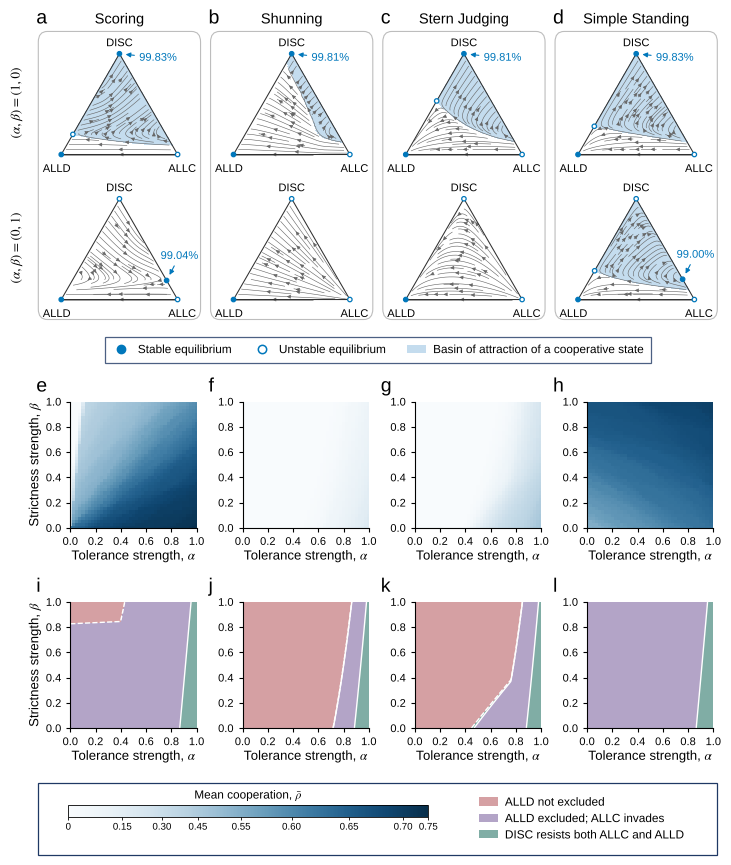

Saved ED_Fig3 (PDF, SVG, PNG) and the single panels.


In [6]:
def pub_letter(figure, axis, letter, x, y):
    # panel letter in figure coordinates, 14 pt, regular weight (ED2/ED9 style)
    figure.text(x, y, letter, fontsize=14, va='baseline', ha='left')


def framed_box(figure, rect, edge=NAVY, lw=.9, rounded=False):
    x0, y0, w, h = rect
    style = 'round,pad=0,rounding_size=0.012' if rounded else 'square,pad=0'
    figure.patches.append(FancyBboxPatch((x0, y0), w, h, boxstyle=style, transform=figure.transFigure,
                                         facecolor='none', edgecolor=edge, lw=lw, zorder=0))


def make_ed3_figure():
    W, H = 7.5, 8.75                                        # inches; layout below is in inches from the bottom
    figure = plt.figure(figsize=(W, H))
    fx = lambda inches: inches / W
    fy = lambda inches: inches / H
    left, right, gap = .64, 7.43, .1
    col_w = (right - left - 3 * gap) / 4
    columns = [left + i * (col_w + gap) for i in range(4)]

    # a-d: one rounded box per norm with the two simplexes
    simplex_w = col_w - .04
    simplex_h = simplex_w * (HEIGHT + .26) / 1.36          # data aspect of draw_simplex (xlim/ylim)
    box_top, pad, row_gap = 8.38, .06, .14
    box_bottom = box_top - 2 * simplex_h - 2 * pad - row_gap
    for i, norm in enumerate(NORMS):
        x0 = columns[i]
        framed_box(figure, (fx(x0), fy(box_bottom), fx(col_w), fy(box_top - box_bottom)), edge=BOX_EDGE, lw=.8, rounded=True)
        figure.text(fx(x0 + col_w / 2), fy(box_top + .08), NORM_NAMES[norm], ha='center', va='baseline', fontsize=10.5)
        pub_letter(figure, None, 'abcd'[i], fx(x0 - .02), fy(box_top + .08))
        for row, regime in enumerate(REGIMES):
            y0 = box_top - pad - (row + 1) * simplex_h - row * row_gap
            axis = figure.add_axes([fx(x0 + .02), fy(y0), fx(simplex_w), fy(simplex_h)])
            draw_simplex(axis, regime, norm)
            if i == 0:
                figure.text(fx(left - .22), fy(y0 + .5 * simplex_h), REGIME_LABELS[regime], rotation=90,
                            ha='center', va='center', fontsize=9.5)
    handles = [Line2D([0], [0], marker='o', ms=6, mfc=COLOR_ONE_STEP, mec=COLOR_ONE_STEP, ls='None', label='Stable equilibrium'),
               Line2D([0], [0], marker='o', ms=6, mfc='white', mec=COLOR_ONE_STEP, mew=1.1, ls='None', label='Unstable equilibrium'),
               Patch(facecolor=BASIN_COLOR, edgecolor='none', label='Basin of attraction of a cooperative state')]
    legend = figure.legend(handles=handles, loc='upper center', bbox_to_anchor=(fx((left + right) / 2), fy(box_bottom - .12)),
                           ncol=3, frameon=True, fancybox=False, fontsize=8.5, borderpad=.6, columnspacing=1.8,
                           handlelength=1.6, handletextpad=.6)
    legend.get_frame().set_edgecolor(NAVY); legend.get_frame().set_linewidth(.9)

    # e-l: square planes, right-aligned in each column (room for the y tick labels)
    size = col_w - .36
    row_tops = (box_bottom - .82, box_bottom - .82 - size - .74)
    for row, (draw, top) in enumerate(((draw_cooperation, row_tops[0]), (draw_invasion, row_tops[1]))):
        for i, norm in enumerate(NORMS):
            axis = figure.add_axes([fx(columns[i] + col_w - size - .04), fy(top - size), fx(size), fy(size)])
            image = draw(axis, norm)
            axis.set_xlabel(r'Tolerance strength, $\alpha$', labelpad=2)
            if i == 0:
                axis.set_ylabel(r'Strictness strength, $\beta$', labelpad=3)
            pub_letter(figure, axis, ('efgh', 'ijkl')[row][i], fx(columns[i] - .02), fy(top + .1))
            if row == 0:
                cooperation_image = image

    # bottom box: colour bar (left) and invasion classes (right)
    box_top_b = row_tops[1] - size - .55
    box_bottom_b = box_top_b - .72
    framed_box(figure, (fx(left), fy(box_bottom_b), fx(right - left), fy(box_top_b - box_bottom_b)))
    middle = .5 * (box_top_b + box_bottom_b)
    bar_x, bar_w = left + .3, 3.6
    figure.text(fx(bar_x + bar_w / 2), fy(middle + .17), r'Mean cooperation, $\bar\rho$', ha='center', va='bottom', fontsize=8.5)
    cax = figure.add_axes([fx(bar_x), fy(middle + .02), fx(bar_w), fy(.12)])
    bar = figure.colorbar(cooperation_image, cax=cax, orientation='horizontal', ticks=COOP_TICKS)
    bar.ax.tick_params(labelsize=7, length=2.5, width=.6, pad=1.5)
    bar.ax.set_xticklabels(['0', '0.15', '0.30', '0.45', '0.55', '0.60', '0.65', '0.70', '0.75'])
    bar.outline.set_linewidth(.6)
    handles = [Patch(facecolor=c, edgecolor='none', label=l) for c, l in zip(REGION_COLORS, REGION_LABELS)]
    figure.legend(handles=handles, loc='center left', bbox_to_anchor=(fx(bar_x + bar_w + .4), fy(middle)), ncol=1,
                  frameon=False, fontsize=8.5, handlelength=1.6, handletextpad=.6, labelspacing=.45)
    return figure


figure = make_ed3_figure()
save_figure(figure, FIGURES, 'ED_Fig3', png=True)
plt.show()
plt.close(figure)
print('Saved ED_Fig3 (PDF, SVG, PNG) and the single panels.')